<div align="center">

<h2>ESCUELA POLITÉCNICA NACIONAL</h2>

<h3>FACULTAD DE INGENIERÍA DE SISTEMAS</h3>

<p><strong>Materia:</strong> Recuperación de la Información</p>

<p><strong>Estudiante:</strong> Estéfano Condoy</p>

</div>

<hr>

# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

Aquí hago la parte de preparar documentos: cargo los textos de Gutenberg que distribuye NLTK, cuento los documentos y sus tamaños, y aplico la normalización definida arriba. Los tamaños se reportan en caracteres y tokens.

In [4]:
import re
import sys
import time
import math
import statistics
from collections import Counter, defaultdict

import nltk
from nltk.corpus import gutenberg
import pandas as pd

try:
    FILE_IDS = gutenberg.fileids()
except LookupError:
    nltk.download('gutenberg')
    FILE_IDS = gutenberg.fileids()

assert len(FILE_IDS) == 18, f"Se esperaban 18 textos de NLTK; se encontraron {len(FILE_IDS)}"

TOKEN_RE = re.compile(r"[^\W_]+(?:'[^\W_]+)?", flags=re.UNICODE)

def tokenize(text):
    'Normaliza a minúsculas y conserva palabras Unicode y apóstrofos internos.'
    return TOKEN_RE.findall(text.lower().replace('\u2019', "'"))

documents = {file_id: tokenize(gutenberg.raw(file_id)) for file_id in FILE_IDS}
doc_ids = list(documents)
corpus_stats = pd.DataFrame([
    {"documento": doc_id, "caracteres": len(gutenberg.raw(doc_id)),
     "tokens": len(documents[doc_id])}
    for doc_id in doc_ids
])
print(f"Documentos: {len(documents)} | Tokens totales: {sum(map(len, documents.values())):,}")
display(corpus_stats)
print("Preprocesamiento: minúsculas; puntuación separa/elimina tokens; sin stopwords ni stemming.")


Documentos: 18 | Tokens totales: 2,182,064


,documento,caracteres,tokens
0,austen-emma.txt,887071,160999
1,austen-persuasion.txt,466292,83660
2,austen-sense.txt,673022,119965
3,bible-kjv.txt,4332554,852256
4,blake-poems.txt,38153,6839
5,bryant-stories.txt,249439,46321
6,burgess-busterbrown.txt,84663,15969
7,carroll-alice.txt,144395,26688
8,chesterton-ball.txt,457450,82248
9,chesterton-brown.txt,406629,72391


Preprocesamiento: minúsculas; puntuación separa/elimina tokens; sin stopwords ni stemming.


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [8]:
# Recorro documentos y tokens con los dos lazos requeridos para búsqueda secuencial.
def sequential_search(term, corpus=documents):
    term_tokens = tokenize(term)
    if len(term_tokens) != 1:
        raise ValueError("La consulta secuencial debe contener exactamente un término")
    query = term_tokens[0]
    found = []
    for doc_id, tokens in corpus.items():
        contains_term = False
        for token in tokens:
            if token == query:
                contains_term = True
                break
        if contains_term:
            found.append(doc_id)
    return found

document_frequency = Counter(token for tokens in documents.values() for token in set(tokens))

# Tomo los términos de ejemplo de las frecuencias reales del corpus.
frequent_term = document_frequency.most_common(1)[0][0]
rare_term = sorted(term for term, df in document_frequency.items() if df == 1)[0]
missing_term = "zzqterminoinexistente"
sample_queries = {"frecuente": frequent_term, "poco frecuente": rare_term,
                  "inexistente": missing_term}
for label, term in sample_queries.items():
    print(f"{label}: {term!r} -> {sequential_search(term)}")


frecuente: 'place' -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
poco frecuente: '0' -> ['whitman-leaves.txt']
inexistente: 'zzqterminoinexistente' -> []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [11]:
# Mido cada consulta 30 veces y convierto nanosegundos a milisegundos.
REPEATS = 30

def mean_query_ms(function, *args, repeats=REPEATS, **kwargs):
    durations = []
    for _ in range(repeats):
        start = time.perf_counter_ns()
        function(*args, **kwargs)
        durations.append(time.perf_counter_ns() - start)
    # El promedio reduce el efecto de pequeñas variaciones entre ejecuciones.
    return statistics.mean(durations) / 1_000_000

sequential_times = pd.DataFrame([
    {"tipo": label, "término": term,
     "documentos_recuperados": len(sequential_search(term)),
     "media_30_ms": mean_query_ms(sequential_search, term)}
    for label, term in sample_queries.items()
])
display(sequential_times)

,tipo,término,documentos_recuperados,media_30_ms
0,frecuente,place,18,1.310850
1,poco frecuente,0,1,50.796173
2,inexistente,zzqterminoinexistente,0,50.882690


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [21]:
# Construyo un índice invertido: cada término apunta a los documentos que lo contienen.
def build_inverted_index(corpus):
    index = defaultdict(set)
    for doc_id, tokens in corpus.items():
         # El set evita procesar varias veces un término repetido en el mismo documento.
        for token in set(tokens):
            index[token].add(doc_id)
    return dict(index)

inverted_index = build_inverted_index(documents)
all_doc_ids = set(documents)

def postings(term, index=inverted_index):
    normalized = tokenize(term)
    if len(normalized) != 1:
        raise ValueError("Se requiere exactamente un término")
    return set(index.get(normalized[0], set()))

def boolean_and(term_a, term_b, index=inverted_index):
    return postings(term_a, index) & postings(term_b, index)

def boolean_or(term_a, term_b, index=inverted_index):
    return postings(term_a, index) | postings(term_b, index)

def boolean_not(term, index=inverted_index, universe=all_doc_ids):
    # NOT devuelve todos los documentos del corpus que no contienen el término.
    return set(universe) - postings(term, index)

terms_to_inspect = [frequent_term, rare_term, "the"]
display(pd.DataFrame([
    {"término": term, "postings": sorted(postings(term)), "DF": len(postings(term))}
    for term in dict.fromkeys(terms_to_inspect)
]))
# Elijo otro término frecuente para mostrar ejemplos de AND y OR.
second_term = next((term for term, _ in document_frequency.most_common(2)
                    if term != frequent_term), frequent_term)
print("AND:", sorted(boolean_and(frequent_term, second_term)))
print("OR:", sorted(boolean_or(frequent_term, second_term)))
print("NOT (Complemento en los 18 documentos):", sorted(boolean_not(frequent_term)))


,término,postings,DF
0,place,"[austen-emma.txt, austen-persuasion.txt, auste...",18
1,0,[whitman-leaves.txt],1
2,the,"[austen-emma.txt, austen-persuasion.txt, auste...",18


AND: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
OR: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
NOT (Complemento en los 18 documentos): []


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [26]:
# Comparo los resultados exactos y los tiempos de los dos métodos.
comparison_rows = []
for label, term in sample_queries.items():
    seq_result = set(sequential_search(term))
    idx_result = postings(term)
    # Si falla la igualdad, se detiene la comparación y se identifica la consulta.
    assert seq_result == idx_result, f"Diferencia para {term!r}"
    # Guardo una fila por método: consulta, cantidad de documentos y tiempo promedio.
    comparison_rows.extend([
        {"consulta": label, "término": term, "método": "secuencial",
         "documentos": len(seq_result), "media_30_ms": mean_query_ms(sequential_search, term)},
        {"consulta": label, "término": term, "método": "índice invertido",
         "documentos": len(idx_result), "media_30_ms": mean_query_ms(postings, term)},
    ])
comparison_small = pd.DataFrame(comparison_rows)
display(comparison_small)
print("Verificación: En ambos métodos devuelven los mismos documentos en las tres consultas que se hicieron.")

,consulta,término,método,documentos,media_30_ms
0,frecuente,place,secuencial,18,0.780957
1,frecuente,place,índice invertido,18,0.001347
2,poco frecuente,0,secuencial,1,50.330947
3,poco frecuente,0,índice invertido,1,0.001313
4,inexistente,zzqterminoinexistente,secuencial,0,52.329513
5,inexistente,zzqterminoinexistente,índice invertido,0,0.003523


Verificación: En ambos métodos devuelven los mismos documentos en las tres consultas que se hicieron.


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [40]:
# Importo el lector de ZIP y herramientas para reconocer nombres de libros.
import re
from collections import defaultdict
from pathlib import Path
from zipfile import ZipFile, BadZipFile
import tarfile

# Esta es la ruta del ZIP que compartiste.
GUTENBERG_ZIP = Path(r"C:\Users\Estefano Condoy\Downloads\txt-files.tar.zip")

Eligó una versión por libro. La función agrupa los archivos por su ID de Gutenberg y conserva una sola versión.

In [41]:
def canonical_zip_members(zip_path):
    # Busco el archivo TAR que viene dentro del ZIP de Gutenberg.
    with ZipFile(zip_path) as archive:
        tar_name = next((name for name in archive.namelist()
                         if name.lower().endswith('.tar')), None)
        if tar_name is None:
            raise ValueError("No encontré un archivo TAR dentro del ZIP")

        # Recorro el TAR en modo secuencial y agrupo los archivos TXT por ID.
        grouped = defaultdict(list)
        with archive.open(tar_name) as tar_stream:
            with tarfile.open(fileobj=tar_stream, mode='r|') as tar:
                for member in tar:
                    if not member.isfile() or not member.name.lower().endswith('.txt'):
                        continue
                    base = Path(member.name).name
                    # Reconozco nombres como 123.txt, 123-0.txt y pg123-0.txt.
                    match = re.match(r"^(?:pg)?(\d+)(?:-(\d+))?\.txt$",
                                     base, flags=re.IGNORECASE)
                    if match:
                        ebook_id, version = match.groups()
                        grouped[int(ebook_id)].append((member.name, version))

    selected = {}
    for ebook_id, versions in grouped.items():
        # Prefiero -0.txt; si no existe, conservo una versión disponible.
        versions.sort(key=lambda item: (item[1] != "0", item[1] not in (None, "0"), item[0]))
        selected[ebook_id] = versions[0][0]

    # Devuelvo un nombre de archivo por cada ID Gutenberg.
    return selected


Cuento los archivos únicos y compruebo la ruta, ejecuta la función y muestra el total y algunos ejemplos.

In [42]:
# Compruebo que la ruta exista antes de leer el archivo.
if GUTENBERG_ZIP.exists():
    try:
        canonical_members = canonical_zip_members(GUTENBERG_ZIP)
        # La cantidad de claves equivale al número de libros únicos reconocidos.
        print(f"Libros únicos con nombre identificable: {len(canonical_members):,}")
        # Muestro algunos pares ID/ruta para revisar cómo quedaron identificados.
        print("Muestra de identificadores y archivos:", list(canonical_members.items())[:10])
    except BadZipFile:
        canonical_members = None
        print("El archivo existe, pero no parece ser un ZIP válido.")
else:
    canonical_members = None
    print("No encuentro el archivo. Revisa la ruta indicada en el Paso 1.")


Libros únicos con nombre identificable: 78,145
Muestra de identificadores y archivos: [(10000, 'cache/epub/10000/pg10000.txt'), (10001, 'cache/epub/10001/pg10001.txt'), (10002, 'cache/epub/10002/pg10002.txt'), (10003, 'cache/epub/10003/pg10003.txt'), (10004, 'cache/epub/10004/pg10004.txt'), (10005, 'cache/epub/10005/pg10005.txt'), (10006, 'cache/epub/10006/pg10006.txt'), (10007, 'cache/epub/10007/pg10007.txt'), (10008, 'cache/epub/10008/pg10008.txt'), (10009, 'cache/epub/10009/pg10009.txt')]


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [45]:
# Cargo solo el subconjunto pedido y estimo el costo de memoria del índice.
def load_zip_subset(zip_path, member_map, limit):
    # Selecciono los primeros IDs y preparo un mapa de ruta a ID.
    selected = sorted(member_map.items())[:limit]
    wanted = {member: str(ebook_id) for ebook_id, member in selected}
    corpus = {}

    with ZipFile(zip_path) as archive:
        tar_name = next((name for name in archive.namelist()
                         if name.lower().endswith('.tar')), None)
        if tar_name is None:
            raise ValueError("No encontré un archivo TAR dentro del ZIP")

        # Recorro el TAR y cargo únicamente los documentos seleccionados.
        with archive.open(tar_name) as tar_stream:
            with tarfile.open(fileobj=tar_stream, mode='r|') as tar:
                for member in tar:
                    if member.name not in wanted or not member.isfile():
                        continue
                    stream = tar.extractfile(member)
                    if stream is None:
                        continue
                    # Decodifico texto con reemplazos si algún carácter está dañado.
                    raw = stream.read().decode('utf-8', errors='replace')
                    corpus[wanted[member.name]] = tokenize(raw)
                    if len(corpus) == len(selected):
                        break

    return corpus

def benchmark_subset(zip_path, member_map, limit, query="the"):
    corpus = load_zip_subset(zip_path, member_map, limit)
    index_start = time.perf_counter_ns()
    index = build_inverted_index(corpus)
    index_build_ms = (time.perf_counter_ns() - index_start) / 1_000_000
    seq = sequential_search(query, corpus)
    # Reutilizo postings de la Parte A, pasándole el índice de este subconjunto.
    idx = postings(query, index)
    # Verifico equivalencia antes de aceptar las mediciones de este tamaño.
    assert set(seq) == idx, f"Resultados distintos en subconjunto de {limit} libros"
    seq_ms = mean_query_ms(sequential_search, query, corpus)
    idx_ms = mean_query_ms(postings, query, index)
    token_count = sum(map(len, corpus.values()))
    approx_token_bytes = sum(sys.getsizeof(t) for ts in corpus.values() for t in ts)
    approx_index_bytes = sys.getsizeof(index) + sum(
        sys.getsizeof(term) + sys.getsizeof(ids) + sum(sys.getsizeof(i) for i in ids)
        for term, ids in index.items())
    return {"documentos": len(corpus), "tokens": token_count, "consulta": query,
            "secuencial_ms": seq_ms, "índice_ms": idx_ms,
            "construcción_índice_ms": index_build_ms,
            "memoria_tokens_aprox_MB": approx_token_bytes / 1e6,
            "memoria_índice_aprox_MB": approx_index_bytes / 1e6}

def compare_large_subset(zip_path, member_map, limit, queries):
    # Cargo y normalizo el subconjunto con la misma función usada en la Parte A.
    corpus = load_zip_subset(zip_path, member_map, limit)

    # Construyo un índice para este subconjunto y mido su costo por separado.
    index_start = time.perf_counter_ns()
    index = build_inverted_index(corpus)
    index_build_ms = (time.perf_counter_ns() - index_start) / 1_000_000

    # Estimo memoria de tokens e índice, y registro el tamaño del ZIP en disco.
    token_count = sum(map(len, corpus.values()))
    corpus_bytes = sys.getsizeof(corpus) + sum(
        sys.getsizeof(doc_id) + sys.getsizeof(tokens)
        + sum(sys.getsizeof(token) for token in tokens)
        for doc_id, tokens in corpus.items())
    index_bytes = sys.getsizeof(index) + sum(
        sys.getsizeof(term) + sys.getsizeof(ids)
        + sum(sys.getsizeof(doc_id) for doc_id in ids)
        for term, ids in index.items())
    archive_mb = zip_path.stat().st_size / 1_000_000

    rows = []
    for label, term in queries.items():
        # Ejecuto la misma consulta en ambos métodos y comparo sus IDs.
        seq_ids = set(sequential_search(term, corpus))
        # Reutilizo postings de la Parte A con el índice construido para n.
        idx_ids = postings(term, index)
        assert seq_ids == idx_ids, f"Resultados distintos para {term!r}, n={limit}"

        # Tomo 30 tiempos por método; carga, normalización e indexación quedan fuera.
        rows.extend([
            {"documentos": len(corpus), "tokens": token_count, "consulta": label,
             "término": term, "método": "secuencial",
             "documentos_recuperados": len(seq_ids),
             "media_30_ms": mean_query_ms(sequential_search, term, corpus),
             "construcción_índice_ms": index_build_ms,
             "memoria_corpus_aprox_MB": corpus_bytes / 1e6,
             "memoria_índice_aprox_MB": index_bytes / 1e6,
             "ZIP_en_disco_MB": archive_mb},
            {"documentos": len(corpus), "tokens": token_count, "consulta": label,
             "término": term, "método": "índice invertido",
             "documentos_recuperados": len(idx_ids),
             "media_30_ms": mean_query_ms(postings, term, index),
             "construcción_índice_ms": index_build_ms,
             "memoria_corpus_aprox_MB": corpus_bytes / 1e6,
             "memoria_índice_aprox_MB": index_bytes / 1e6,
             "ZIP_en_disco_MB": archive_mb},
        ])
    return pd.DataFrame(rows)

# Pruebo las consultas frecuente, poco frecuente e inexistente en tres tamaños.
PART_B_SIZES = [50, 100, 250]
if canonical_members is not None:
    available_sizes = sorted({min(n, len(canonical_members)) for n in PART_B_SIZES})
    part_b_results = pd.concat([
        compare_large_subset(GUTENBERG_ZIP, canonical_members, n, sample_queries)
        for n in available_sizes
    ], ignore_index=True)
    display(part_b_results)
    print("Resultados equivalentes en todas las consultas y tamaños.")
else:
    part_b_results = pd.DataFrame()
    print("Pendiente: revisa la ruta del ZIP en el Paso 1.")


,documentos,tokens,consulta,término,método,documentos_recuperados,media_30_ms,construcción_índice_ms,memoria_corpus_aprox_MB,memoria_índice_aprox_MB,ZIP_en_disco_MB
0,50,5472400,frecuente,place,secuencial,50,3.609727,370.1382,294.832678,57.818216,11322.987679
1,50,5472400,frecuente,place,índice invertido,50,0.001393,370.1382,294.832678,57.818216,11322.987679
2,50,5472400,poco frecuente,0,secuencial,11,65.341900,370.1382,294.832678,57.818216,11322.987679
3,50,5472400,poco frecuente,0,índice invertido,11,0.001080,370.1382,294.832678,57.818216,11322.987679
4,50,5472400,inexistente,zzqterminoinexistente,secuencial,0,84.860673,370.1382,294.832678,57.818216,11322.987679
5,50,5472400,inexistente,zzqterminoinexistente,índice invertido,0,0.001283,370.1382,294.832678,57.818216,11322.987679
6,100,10133377,frecuente,place,secuencial,100,10.940283,1157.9987,546.181535,105.616471,11322.987679
7,100,10133377,frecuente,place,índice invertido,100,0.001703,1157.9987,546.181535,105.616471,11322.987679
8,100,10133377,poco frecuente,0,secuencial,24,137.707990,1157.9987,546.181535,105.616471,11322.987679
9,100,10133377,poco frecuente,0,índice invertido,24,0.001213,1157.9987,546.181535,105.616471,11322.987679


Resultados equivalentes en todas las consultas y tamaños.


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

,documentos,tokens,consulta,secuencial_ms,índice_ms,construcción_índice_ms,memoria_tokens_aprox_MB,memoria_índice_aprox_MB
0,50,5472400,the,0.005823,0.001213,391.8160,248.484777,57.818216
1,100,10133377,the,0.015700,0.002520,888.4481,460.195735,105.616471
2,250,23529694,the,0.065773,0.005420,2618.9549,1068.263590,265.938534
3,500,40318550,the,0.073903,0.005460,5588.0680,1829.089956,463.361776
4,1000,81718646,the,0.231057,0.025653,9901.8126,3713.872082,868.560313


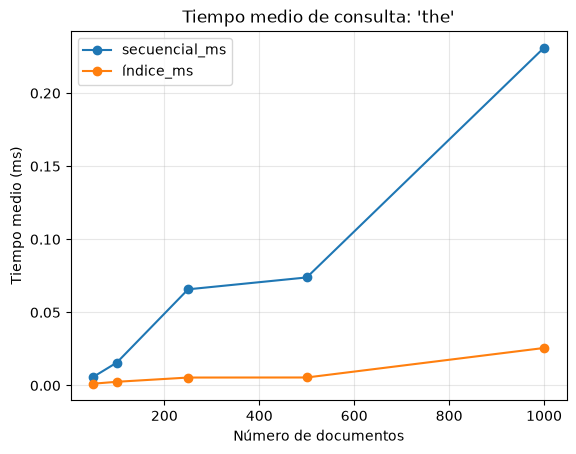

In [47]:
# Mido una consulta común en tamaños crecientes y dibujo ambos tiempos.
SIZES = [50, 100, 250, 500, 1000]
SCALING_QUERY = "the"

if canonical_members is not None:
    scaling_rows = []
    for n in SIZES:
        if n > len(canonical_members):
            continue
        scaling_rows.append(benchmark_subset(GUTENBERG_ZIP, canonical_members, n,
                                             query=SCALING_QUERY))
    scaling_results = pd.DataFrame(scaling_rows)
    display(scaling_results)
    # Las dos curvas comparten ejes para que la comparación sea directa.
    ax = scaling_results.plot(x="documentos", y=["secuencial_ms", "índice_ms"],
                              marker="o", title=f"Tiempo medio de consulta: {SCALING_QUERY!r}")
    ax.set_xlabel("Número de documentos")
    ax.set_ylabel("Tiempo medio (ms)")
    ax.grid(True, alpha=0.3)
else:
    scaling_results = pd.DataFrame()
    print("Pendiente: descargar el ZIP, corregir la ruta y ejecutar esta celda.")


**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

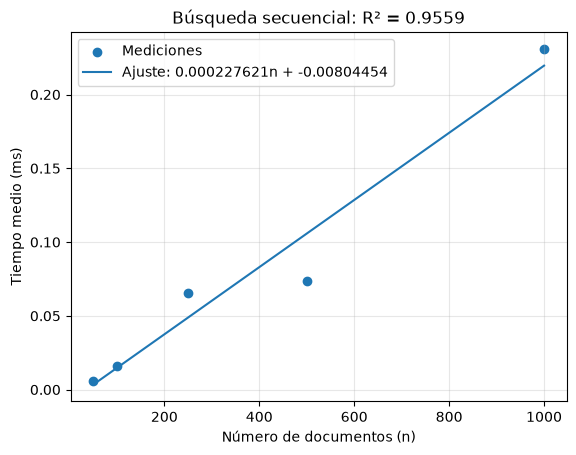

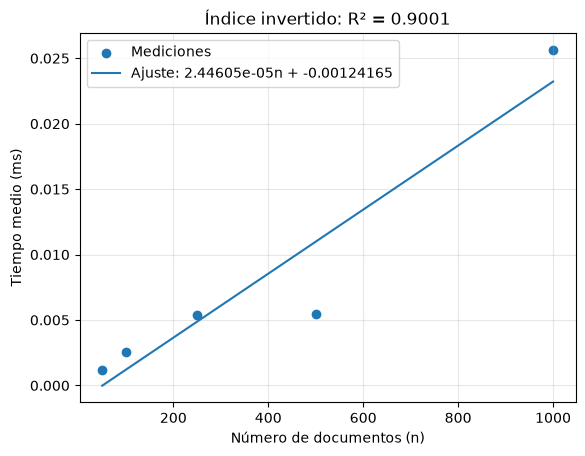

,método,a_ms_por_documento,b_ms,R²
0,Búsqueda secuencial,0.000228,-0.008045,0.955933
1,Índice invertido,0.000024,-0.001242,0.900107


In [51]:
# Ajusto una recta a cada método y calculo su coeficiente R^2.
import numpy as np
import matplotlib.pyplot as plt

def fit_and_plot(data, time_column, method_label):
    x = data["documentos"].to_numpy(dtype=float)
    y = data[time_column].to_numpy(dtype=float)
    a, b = np.polyfit(x, y, 1)
    predicted = a * x + b
    ss_res = float(np.sum((y - predicted) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    # R^2 compara el error del ajuste con la variación total de los datos.
    r2 = 1.0 if ss_tot == 0 and ss_res == 0 else (1 - ss_res / ss_tot if ss_tot else float('nan'))
    order = np.argsort(x)
    plt.scatter(x, y, label="Mediciones")
    plt.plot(x[order], predicted[order], label=f"Ajuste: {a:.6g}n + {b:.6g}")
    plt.xlabel("Número de documentos (n)")
    plt.ylabel("Tiempo medio (ms)")
    plt.title(f"{method_label}: R² = {r2:.4f}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
    return {"método": method_label, "a_ms_por_documento": a,
            "b_ms": b, "R²": r2}

if not scaling_results.empty and len(scaling_results) >= 2:
    fit_results = pd.DataFrame([
        fit_and_plot(scaling_results, "secuencial_ms", "Búsqueda secuencial"),
        fit_and_plot(scaling_results, "índice_ms", "Índice invertido"),
    ])
    display(fit_results)
else:
    print("El ajuste requiere resultados medidos para al menos dos tamaños del corpus.")


## Análisis del modelo lineal y conclusiones

El ajuste lineal representa razonablemente las mediciones: la búsqueda secuencial obtuvo \(R^2=0.956\) y el índice invertido \(R^2=0.900\). El modelo describe mejor los datos secuenciales; en ambos casos, el tiempo tiende a crecer con el número de documentos. Los interceptos negativos son resultado del ajuste y no significan que el tiempo real pueda ser negativo.

La búsqueda secuencial puede recorrer todos los tokens, así que su costo en el peor caso es \(O(T)\), donde \(T\) es el total de tokens. El índice también requiere recorrer los tokens para construirse, pero luego busca en los postings del término; el costo de cada consulta depende de cuántos documentos lo contienen.

En las pruebas, el índice fue más rápido para la consulta frecuente “the”: con 1.000 documentos tardó \(0.026\) ms, frente a \(0.231\) ms de la búsqueda secuencial. Sin embargo, construir el índice tomó aproximadamente 9.9 segundos y requiere memoria adicional. Por ello, resulta especialmente útil cuando se harán muchas consultas sobre la misma colección. Estos resultados describen los tamaños y la consulta evaluados; no garantizan la misma tendencia para todos los términos o corpus.

Con esto concluyo que el modelo lineal describe de forma razonable la tendencia observada en este experimento, pero no demuestra que ambos algoritmos tengan siempre un comportamiento lineal. Las mediciones corresponden a cinco tamaños de corpus y a una consulta frecuente; otros términos, en especial los poco frecuentes o inexistentes, pueden producir tiempos distintos.